# Farm A data exploration (CARE v6)

This notebook explores the original Wind Farm A files. It does not modify raw data, clean values, or train a model. Missing values and zeros are measured separately; zero is not assumed to mean missing.

In [6]:
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
cwd=Path.cwd()
ROOT=next((p for p in (cwd,*cwd.parents) if (p/"data/raw/Wind Farm A/datasets").is_dir()),None)
if ROOT is None: raise FileNotFoundError("Cannot find data/raw/Wind Farm A/datasets")
FARM=ROOT/"data/raw/Wind Farm A"; DATA=FARM/"datasets"
EVENTS=pd.read_csv(FARM/"event_info.csv",sep=";"); FEATURES=pd.read_csv(FARM/"feature_description.csv",sep=";")
README=(ROOT/"data/raw/README.md").read_text(encoding="utf-8",errors="replace")
FILES=sorted(DATA.glob("*.csv"),key=lambda p:int(p.stem) if p.stem.isdigit() else p.stem)
print("Project:",ROOT,"| Farm A event files:",len(FILES),"| metadata rows:",len(EVENTS))
print("Event metadata columns:",EVENTS.columns.tolist()); print("Feature description columns:",FEATURES.columns.tolist())
print("Turbines:",sorted(EVENTS.asset.dropna().astype(str).unique()))
print("Farm A event labels:"); display(EVENTS.event_label.value_counts(dropna=False).to_frame("events"))
print("README lines mentioning labels or splits:")
for line in README.splitlines():
    if any(w in line.lower() for w in ["anomal","normal","train","prediction"]): print(line[:250])
print("Event metadata preview:"); display(EVENTS.head())

Project: c:\Users\mohamad\Desktop\Predictive-Maintenance | Farm A event files: 22 | metadata rows: 22
Event metadata columns: ['asset', 'event_id', 'event_label', 'event_start', 'event_start_id', 'event_end', 'event_end_id', 'event_description']
Feature description columns: ['sensor_name', 'statistics_type', 'description', 'unit', 'is_angle', 'is_counter']
Turbines: ['0', '10', '11', '13', '21']
Farm A event labels:


,events
event_label,
anomaly,12
normal,10


README lines mentioning labels or splits:
The overall dataset is balanced, as 44 out the 95 datasets contain a labeled anomaly event and the other 51 datasets represent normal behavior.
Each dataset csv-file contains time series of one wind turbine, containing both training and prediction data.
The prediction data contains exactly one event which can either be an anomaly event (leading up to a failure) or just normal behavior (normal event).
* ``train_test``: Strings describing whether the timestamp is part of the prediction data or the training data of the dataset.
* ``status_type``: Status of the wind turbine at the given time stamp. There are 6 different status IDs where status 0 and 2 are considered normal operation:
  * 0: Normal Operation - The turbine is in normal power production mode 
* ``event_label``: String describing whether the event of the dataset is an anomaly event (``anomaly``) or a normal event (``normal``)
* ``event_description``: Additional information of the root 

,asset,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,11,68,anomaly,2023-07-28 13:20:00,52063,2023-08-11 13:10:00,54076,Transformer failure
1,21,22,anomaly,2023-08-12 09:50:00,51888,2023-08-19 10:00:00,52892,Hydraulic group
2,21,72,anomaly,2023-10-10 08:40:00,52497,2023-10-17 08:40:00,53505,Gearbox failure
3,0,73,anomaly,2023-06-10 11:40:00,52745,2023-06-17 11:40:00,53753,Hydraulic group
4,0,0,anomaly,2023-08-06 06:10:00,52436,2023-08-20 06:10:00,54447,Generator bearing failure


## Main columns in plain language

- `time_stamp`: sensor recording time.
- `asset_id` in event CSVs and `asset` in metadata: turbine identifier.
- `id`: row identifier inside an event file.
- `train_test`: supplied `train` or `prediction` split.
- `status_type_id`: numeric status code on each data row. `event_label` in metadata gives the event label as text (for example, anomaly or normal).
- Sensor columns: measured or derived signals. The feature-description table gives a sensor name, statistic type, description, and unit when available. Some units are damaged or blank, so physical meaning/ranges can remain uncertain.

In [7]:
STRUCTURAL={"time_stamp","asset_id","id","train_test","status_type_id"}
header=pd.read_csv(FILES[0],sep=";",nrows=0).columns.tolist(); SENSORS=[c for c in header if c not in STRUCTURAL]
print("Example file:",FILES[0].name,"| columns:",len(header),"| sensor columns:",len(SENSORS))
print("First sensor columns:",SENSORS[:20],"| feature-description rows:",len(FEATURES))
display(FEATURES.head(12))
if "unit" in FEATURES:
 print("Units (including blanks):"); display(FEATURES.unit.fillna("<blank>").value_counts().to_frame("rows"))
print("Replacement character in descriptions:","?" in FEATURES.to_string())

Example file: 0.csv | columns: 86 | sensor columns: 81
First sensor columns: ['sensor_0_avg', 'sensor_1_avg', 'sensor_2_avg', 'wind_speed_3_avg', 'wind_speed_4_avg', 'wind_speed_3_max', 'wind_speed_3_min', 'wind_speed_3_std', 'sensor_5_avg', 'sensor_5_max', 'sensor_5_min', 'sensor_5_std', 'sensor_6_avg', 'sensor_7_avg', 'sensor_8_avg', 'sensor_9_avg', 'sensor_10_avg', 'sensor_11_avg', 'sensor_12_avg', 'sensor_13_avg'] | feature-description rows: 54


,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,average,Ambient temperature,�C,False,False
1,sensor_1,average,Wind absolute direction,�,True,False
2,sensor_2,average,Wind relative direction,�,True,False
3,wind_speed_3,"maximum,minimum,average,std_dev",Windspeed,m/s,False,False
4,wind_speed_4,average,Estimated windspeed,m/s,False,False
5,sensor_5,"maximum,minimum,std_dev,average",Pitch angle,�,True,False
6,sensor_6,average,Temperature in the hub controller,�C,False,False
7,sensor_7,average,Temperature in the top nacelle controller,�C,False,False
8,sensor_8,average,Temperature in the choke coils on the VCS-section,�C,False,False
9,sensor_9,average,Temperature on the VCP-board,�C,False,False


Units (including blanks):


,rows
unit,
�C,25
�,4
Wh,4
VArh,4
A,3
kVAr,3
V,3
m/s,2
rpm,2


Replacement character in descriptions: False


## Data quality scan

Files are read in chunks. The scan counts missing/non-numeric sensor cells, zeros, duplicate rows, duplicate timestamps, invalid timestamps, and intervals longer than the expected 10 minutes. It observes the data only; it does not change values.

In [8]:
def scan(path,chunksize=100_000):
 cols=pd.read_csv(path,sep=";",nrows=0).columns.tolist(); sens=[c for c in cols if c not in STRUCTURAL]
 out=dict(file=path.name,rows=0,train=0,prediction=0,missing=0,zeros=0,non_numeric=0,non_finite=0,duplicate_rows=0,duplicate_timestamps=0,invalid_timestamps=0,gaps_over_10m=0,intervals_under_10m=0,backwards=0,max_gap_minutes=0.)
 miss=pd.Series(0,index=sens,dtype="int64"); zero=miss.copy(); seen_rows=set(); seen_ts=set(); prev=None
 for d in pd.read_csv(path,sep=";",chunksize=chunksize):
  out["rows"]+=len(d); counts=d.train_test.value_counts(); out["train"]+=int(counts.get("train",0)); out["prediction"]+=int(counts.get("prediction",0))
  raw=d[sens]; blank=raw.astype("string").apply(lambda x:x.str.strip().eq("")); m=raw.isna()|blank
  miss=miss.add(m.sum(),fill_value=0).astype("int64"); out["missing"]+=int(m.to_numpy().sum())
  num=raw.apply(pd.to_numeric,errors="coerce"); out["non_numeric"]+=int((num.isna()&~m).to_numpy().sum())
  a=num.to_numpy(dtype="float64",na_value=np.nan); out["non_finite"]+=int((~np.isfinite(a)&~np.isnan(a)).sum())
  z=num.eq(0).sum(); zero=zero.add(z,fill_value=0).astype("int64"); out["zeros"]+=int(z.sum())
  for h in pd.util.hash_pandas_object(d,index=False):
   if h in seen_rows: out["duplicate_rows"]+=1
   seen_rows.add(h)
  ts=pd.to_datetime(d.time_stamp,errors="coerce"); out["invalid_timestamps"]+=int(ts.isna().sum())
  for t in ts:
   if pd.isna(t): continue
   if t in seen_ts: out["duplicate_timestamps"]+=1
   seen_ts.add(t)
   if prev is not None:
    minutes=(t-prev).total_seconds()/60
    if minutes<0: out["backwards"]+=1
    elif minutes>10: out["gaps_over_10m"]+=1; out["max_gap_minutes"]=max(out["max_gap_minutes"],minutes)
    elif minutes<10: out["intervals_under_10m"]+=1
   prev=t
 return out,miss,zero
scans=[scan(f) for f in FILES]; Q=pd.DataFrame([x[0] for x in scans]).set_index("file")
missing_total=sum((x[1] for x in scans),start=pd.Series(0,index=SENSORS,dtype="int64")); zero_total=sum((x[2] for x in scans),start=pd.Series(0,index=SENSORS,dtype="int64"))
print("Farm A quality totals:"); display(Q.sum(numeric_only=True).to_frame("count").T)
print("Events with missing values:",int((Q.missing>0).sum())); print("Missing columns:"); display(missing_total[missing_total>0].to_frame("cells"))
print("Most zero-heavy sensors:"); display(zero_total.sort_values(ascending=False).head(12).to_frame("zero cells"))
print("Largest timestamp gaps:"); display(Q[Q.max_gap_minutes>0][["gaps_over_10m","max_gap_minutes"]].sort_values("max_gap_minutes",ascending=False).head(10))

Farm A quality totals:


,rows,train,prediction,missing,zeros,non_numeric,non_finite,duplicate_rows,duplicate_timestamps,invalid_timestamps,gaps_over_10m,intervals_under_10m,backwards,max_gap_minutes
count,1196747.0,1146154.0,50593.0,40.0,10111265.0,0.0,0.0,0.0,0.0,0.0,460.0,0.0,0.0,32900.0


Events with missing values: 12
Missing columns:


,cells
sensor_14_avg,20
sensor_22_avg,20


Most zero-heavy sensors:


,zero cells
sensor_46,1196747
sensor_49,1196747
sensor_47,755320
sensor_44,755022
reactive_power_28_std,515036
reactive_power_27_min,496274
reactive_power_28_max,496274
power_29_min,467698
reactive_power_27_std,461218
reactive_power_27_avg,321456


Largest timestamp gaps:


,gaps_over_10m,max_gap_minutes
file,,
13.csv,34,13730.0
22.csv,24,1790.0
51.csv,25,1790.0
72.csv,24,1790.0
3.csv,41,780.0
0.csv,18,780.0
92.csv,12,780.0
73.csv,10,780.0
14.csv,15,780.0


## Compare metadata, CSV labels, and supplied splits

The metadata label is text (`event_label`); the CSV has numeric `status_type_id`. We show the labels/codes in the files and compare turbine IDs and supplied split sizes. The README and actual v6 metadata disagree by one anomaly and one normal event overall, so neither source is silently overridden.

In [9]:
ids={int(f.stem) for f in FILES if f.stem.isdigit()}; meta=EVENTS.copy(); meta["event_num"]=pd.to_numeric(meta.event_id,errors="coerce"); mids=set(meta.event_num.dropna().astype(int))
print("File IDs absent from metadata:",sorted(ids-mids)); print("Metadata IDs without files:",sorted(mids-ids))
checks=[]
for f in FILES:
 if not f.stem.isdigit(): continue
 eid=int(f.stem); mr=meta.loc[meta.event_num==eid]; d=pd.read_csv(f,sep=";",usecols=["asset_id","status_type_id","train_test"])
 checks.append(dict(event_id=eid,file_assets=sorted(d.asset_id.dropna().astype(str).unique()),metadata_asset=str(mr.iloc[0].asset) if len(mr) else None,file_status=sorted(pd.to_numeric(d.status_type_id,errors="coerce").dropna().unique()),event_label=mr.iloc[0].event_label if len(mr) else None,train=int((d.train_test=="train").sum()),prediction=int((d.train_test=="prediction").sum())))
CHECKS=pd.DataFrame(checks).sort_values("event_id"); CHECKS["asset_match"]=CHECKS.apply(lambda r:r.metadata_asset in r.file_assets,axis=1)
print("Farm A metadata label totals:"); display(EVENTS.event_label.value_counts().to_frame("events"))
print("CSV status-code row totals:"); display(pd.concat([pd.read_csv(f,sep=";",usecols=["status_type_id"]).status_type_id.value_counts() for f in FILES],axis=1).fillna(0).sum(axis=1).sort_index().to_frame("rows"))
print("Asset mismatches:"); display(CHECKS.loc[~CHECKS.asset_match]); print("Per-event train/prediction rows:"); display(CHECKS.set_index("event_id")[["train","prediction"]])
train_keys=defaultdict(set); pred_keys=defaultdict(set)
for f in FILES:
 eid=int(f.stem); d=pd.read_csv(f,sep=";",usecols=["asset_id","time_stamp","train_test"]); d.time_stamp=pd.to_datetime(d.time_stamp,errors="coerce"); d=d.dropna(subset=["asset_id","time_stamp"])
 for asset,t in zip(d.loc[d.train_test=="train","asset_id"].astype(str),d.loc[d.train_test=="train","time_stamp"]): train_keys[(asset,t)].add(eid)
 for asset,t in zip(d.loc[d.train_test=="prediction","asset_id"].astype(str),d.loc[d.train_test=="prediction","time_stamp"]): pred_keys[(asset,t)].add(eid)
overlap=[]
for key,pe in pred_keys.items():
 other=train_keys.get(key,set())-pe
 if other: overlap.append((key[0],key[1],sorted(pe),sorted(other)))
print("Prediction turbine/timestamps also in another event's train:",len(overlap)); display(pd.DataFrame(overlap[:10],columns=["asset_id","timestamp","prediction_events","other_train_events"]))

File IDs absent from metadata: []
Metadata IDs without files: []
Farm A metadata label totals:


,events
event_label,
anomaly,12
normal,10


CSV status-code row totals:


,rows
status_type_id,
0,1053736
3,23689
4,119322


Asset mismatches:


,event_id,file_assets,metadata_asset,file_status,event_label,train,prediction,asset_match


Per-event train/prediction rows:


,train,prediction
event_id,,
0,52148,2838
3,52185,3302
10,52323,1269
13,50427,3583
14,52296,1901
17,52309,2781
22,51888,1148
24,52289,2714
25,52289,2423


Prediction turbine/timestamps also in another event's train: 38367


,asset_id,timestamp,prediction_events,other_train_events
0,0,2023-08-04 06:10:00,[0],[26]
1,0,2023-08-04 06:20:00,[0],[26]
2,0,2023-08-04 06:30:00,[0],[26]
3,0,2023-08-04 06:40:00,[0],[26]
4,0,2023-08-04 06:50:00,[0],[26]
5,0,2023-08-04 07:00:00,[0],[26]
6,0,2023-08-04 07:10:00,[0],[26]
7,0,2023-08-04 07:20:00,[0],[26]
8,0,2023-08-04 07:30:00,[0],[26]
9,0,2023-08-04 07:40:00,[0],[26]


## Visual example and takeaways

These plots show one example normal event and one anomaly event for one sensor. They are for exploration, not model results.

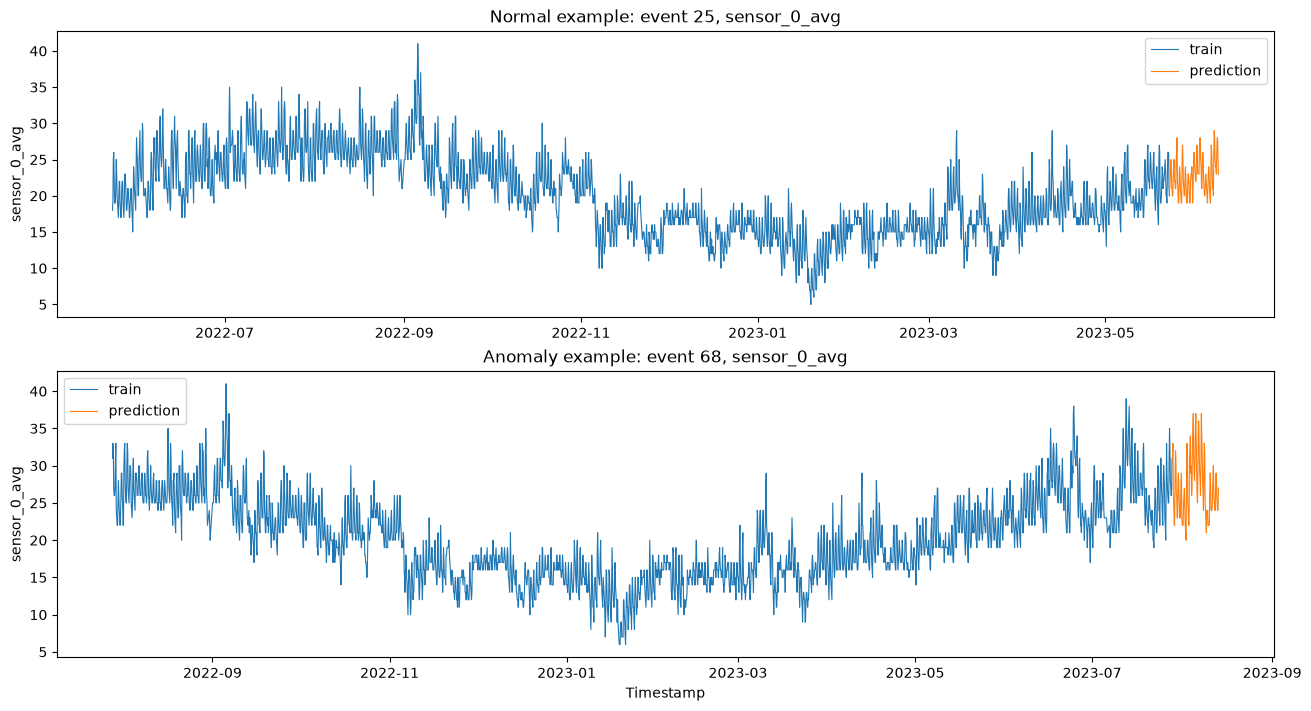


Farm A verified summary
22 event files; 5 turbines; 22 metadata rows.
1,196,747 rows: 1,146,154 train and 50,593 prediction.
40 missing sensor cells; 10,111,265 zeros (not treated as missing).
0 duplicate rows; 0 repeated timestamps within events.
460 intervals exceed 10 minutes. Prediction/train timestamp overlap across events: 38,367.


In [10]:
def choose(labels):
 choices=EVENTS.loc[EVENTS.event_label.astype(str).str.lower().isin(labels),"event_id"]
 return next((DATA/f"{int(i)}.csv" for i in choices if (DATA/f"{int(i)}.csv").exists()),None)
normal=choose({"normal"}); anomaly=choose({"anomaly"}); col="sensor_0_avg" if "sensor_0_avg" in SENSORS else SENSORS[0]
fig,axs=plt.subplots(2,1,figsize=(13,7),constrained_layout=True)
for ax,f,title in [(axs[0],normal,"Normal example"),(axs[1],anomaly,"Anomaly example")]:
 if f is None: ax.set_title(title+" not found"); continue
 d=pd.read_csv(f,sep=";",usecols=["time_stamp","train_test",col]); d.time_stamp=pd.to_datetime(d.time_stamp,errors="coerce"); d[col]=pd.to_numeric(d[col],errors="coerce"); d=d.dropna(subset=["time_stamp"]).iloc[::max(1,len(d)//2500)]
 for split,g in d.groupby("train_test",sort=False): ax.plot(g.time_stamp,g[col],label=split,lw=.8)
 ax.set_title(f"{title}: event {f.stem}, {col}"); ax.set_ylabel(col); ax.legend()
axs[-1].set_xlabel("Timestamp"); plt.show()
print("\nFarm A verified summary")
print(f"{len(FILES)} event files; {EVENTS.asset.nunique()} turbines; {len(EVENTS)} metadata rows.")
print(f"{int(Q.rows.sum()):,} rows: {int(Q.train.sum()):,} train and {int(Q.prediction.sum()):,} prediction.")
print(f"{int(Q.missing.sum()):,} missing sensor cells; {int(Q.zeros.sum()):,} zeros (not treated as missing).")
print(f"{int(Q.duplicate_rows.sum())} duplicate rows; {int(Q.duplicate_timestamps.sum())} repeated timestamps within events.")
print(f"{int(Q.gaps_over_10m.sum())} intervals exceed 10 minutes. Prediction/train timestamp overlap across events: {len(overlap):,}.")